# Stage 3: native evaluation evidence

Saved aggregate results only. **Run All makes no API calls.** Non-Retail evaluation is separate from the four deferred 180-day Retail episodes. Models are substituted gateway models; this is not an exact reproduction of published-model scores. Factset is an extension. Wrong answers and failed or incomplete cohorts stay visible.

In [1]:
import hashlib, json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd()
if not (ROOT / "docs/results/stage3").exists():
    ROOT = ROOT.parent
PUBLIC = ROOT / "docs/results/stage3"
manifest = json.loads((PUBLIC / "artifact_manifest.json").read_text())["files"]
for name, digest in manifest.items():
    assert hashlib.sha256((PUBLIC / name).read_bytes().replace(b"\r\n", b"\n")).hexdigest() == digest, name
status = json.loads((PUBLIC / "status.json").read_text())
display(pd.Series(status))

stage                                                                         3
execution_route                                           non-Retail first pass
route_status                                          in_progress_or_incomplete
original_full_stage_status                           incomplete_Retail_deferred
validated_tasks                                                              11
deferred_tasks                                                                4
research_qualifications       [Substituted gateway models; not exact publish...
dtype: object

## Coverage and denominators

Coverage describes completed units and native horizons independently of method classification. Completing the non-Retail route leaves the original Stage 3 scope incomplete while Retail is deferred.

In [2]:
coverage = pd.read_csv(PUBLIC / "native_coverage.csv")
display(coverage)
cohorts = pd.DataFrame(json.loads((PUBLIC / "evaluation_cohorts.json").read_text()))
display(cohorts[["cohort", "task", "status", "expected_units", "configured_horizon", "attempts", "invalid_responses", "unknown_usage_responses"]])

,task,method_classification,status,planned_units,configured_horizon,validated_units,evaluation_cohorts,failed_or_incomplete_cohorts,qualifications
0,retail:dynamic_middle,native logic with substituted model,deferred,1,180.0,0,0,0,Retail excluded from this execution route; ori...
1,retail:dynamic_hard,native logic with substituted model,deferred,1,180.0,0,0,0,Retail excluded from this execution route; ori...
2,retail:still_middle,native logic with substituted model,deferred,1,180.0,0,0,0,Retail excluded from this execution route; ori...
3,retail:still_hard,native logic with substituted model,deferred,1,180.0,0,0,0,Retail excluded from this execution route; ori...
4,firm:FinCode,native logic with substituted model,validated_complete,7,NaN,7,1,0,NaN
5,firm:CodeFinQA,native logic with substituted model,validated_complete,50,NaN,50,1,0,NaN
6,firm:CodeTAT-QA,native logic with substituted model,validated_complete,50,NaN,50,1,0,NaN
7,firm:SEC-NUM,native logic with substituted model,validated_complete,50,NaN,50,1,0,NaN
8,firm:TAT-QA,native logic with substituted model,validated_complete,50,NaN,50,1,0,NaN
9,firm:ConvFinQA,native logic with substituted model,validated_complete,50,NaN,50,1,0,NaN


,cohort,task,status,expected_units,configured_horizon,attempts,invalid_responses,unknown_usage_responses
0,evaluation_01,firm:FinCode,validated_complete,7,None,7,0,0
1,evaluation_02,firm:CodeFinQA,validated_complete,50,None,50,0,0
2,evaluation_03,firm:CodeTAT-QA,validated_complete,50,None,50,0,0
3,evaluation_04,firm:SEC-NUM,validated_complete,50,None,50,0,0
4,evaluation_05,firm:TAT-QA,validated_complete,50,None,50,0,0
5,evaluation_06,firm:ConvFinQA,validated_complete,50,None,50,0,0
6,evaluation_07,firm:FinKnow,validated_complete,50,None,50,0,0
7,evaluation_08,firm:FormulaEval,validated_complete,50,None,50,0,0
8,evaluation_09,firm:finer,validated_complete,50,None,50,0,0
9,evaluation_10,firm:formula,validated_complete,50,None,50,0,0


## Reasoning results by dataset

Native scorer results retain each dataset's metric: **finer uses individual entity labels**, while the other datasets use cases. Exact-case accuracy is shown separately. No cross-family score is calculated. Each dataset has one evaluation cohort; these bars are descriptive and have no independent-run uncertainty estimate. Pilot results are excluded.

,task,method_classification,correct,scored_cases,exact_case_accuracy,accuracy,native_accuracy_unit,native_correct_units,native_scored_units,no_answer
0,firm:FinCode,native logic with substituted model,7,7,1.00,1.00,case,7,7,0
1,firm:CodeFinQA,native logic with substituted model,41,50,0.82,0.82,case,41,50,0
2,firm:CodeTAT-QA,native logic with substituted model,49,50,0.98,0.98,case,49,50,0
3,firm:SEC-NUM,native logic with substituted model,44,50,0.88,0.88,case,44,50,0
4,firm:TAT-QA,native logic with substituted model,48,50,0.96,0.96,case,48,50,0
5,firm:ConvFinQA,native logic with substituted model,35,50,0.70,0.70,case,35,50,0
6,firm:FinKnow,native logic with substituted model,46,50,0.92,0.92,case,46,50,0
7,firm:FormulaEval,native logic with substituted model,47,50,0.94,0.94,case,47,50,0
8,firm:finer,native logic with substituted model,22,50,0.44,0.73,entity_label,146,200,0
9,firm:formula,native logic with substituted model,37,50,0.74,0.74,case,37,50,0


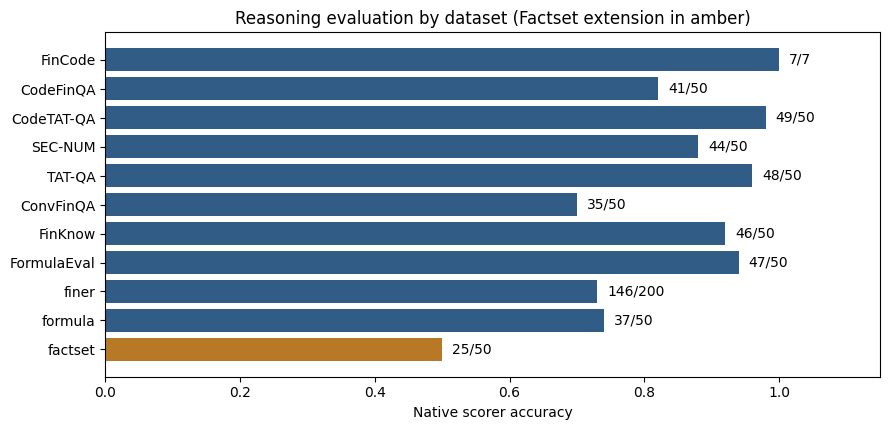

In [3]:
reasoning = cohorts.loc[(cohorts.status == "validated_complete") & cohorts.scored_cases.notna()].copy()
reasoning = reasoning.drop_duplicates("task", keep="last")
if not reasoning.empty:
    display(reasoning[["task", "method_classification", "correct", "scored_cases", "exact_case_accuracy", "accuracy", "native_accuracy_unit", "native_correct_units", "native_scored_units", "no_answer"]])
    labels = reasoning.task.str.replace("firm:", "", regex=False)
    colors = ["#b87926" if name == "firm:factset" else "#315c86" for name in reasoning.task]
    fig, ax = plt.subplots(figsize=(9, max(3, len(reasoning) * .4)))
    ax.barh(labels, reasoning.accuracy, color=colors)
    for position, row in enumerate(reasoning.itertuples()):
        ax.text(row.accuracy + .015, position, f"{int(row.native_correct_units)}/{int(row.native_scored_units)}", va="center")
    ax.set(xlim=(0, 1.15), xlabel="Native scorer accuracy", title="Reasoning evaluation by dataset (Factset extension in amber)")
    ax.invert_yaxis()
    fig.tight_layout()
    plt.show()

## Interactive families

Consulting scores come from the substituted judge model. BeerGame reports retailer and full-chain costs separately; missing upstream aggregate metrics remain null. EDT metrics refer to one synthetic scenario. ICBE summaries describe dependent rounds, not independent replications. Its compatibility adapter uses a 4,096-token ceiling rather than the upstream 150.

In [4]:
families = json.loads((PUBLIC / "family_metrics.json").read_text())
for family in families:
    print(family["task"], family["qualification"])
    display(family)

## Costs and operational reliability

Amounts are gateway-credit estimates using uncached tariffs, not cash purchase prices or independently verified provider billing. The inclusive ledger retains pilot spending and full unknown-charge holds. A held failed charge remains unknown. Account balances, request IDs and transcripts are not published.

In [5]:
budget = json.loads((PUBLIC / "budget_summary.json").read_text())
assert budget["exposure_usd"] <= budget["cap_usd"]
assert budget["attempts"] <= budget["total_attempt_ceiling"]
display(pd.Series(budget))
display(cohorts[["cohort", "task", "status", "attempts", "input_tokens", "output_tokens", "estimated_gateway_credits", "failure_category"]])

currency                                                      USD_gateway_credit
attempts                                                                     744
known_cost_usd                                                          1.288725
unresolved_reserved_usd                                                  0.01901
exposure_usd                                                            1.307734
pending_attempts                                                               0
uncertain_attempts                                                             3
bounded_carried_attempts                                                       3
blocking_uncertain_attempts                                                    0
cap_usd                                                                      6.0
prior_pilot_exposure                                                    0.868873
prior_pilot_attempts                                                         237
scope_caps                  

,cohort,task,status,attempts,input_tokens,output_tokens,estimated_gateway_credits,failure_category
0,evaluation_01,firm:FinCode,validated_complete,7,2697,891,0.004012,None
1,evaluation_02,firm:CodeFinQA,validated_complete,50,61728,5779,0.054368,None
2,evaluation_03,firm:CodeTAT-QA,validated_complete,50,30308,5104,0.032504,None
3,evaluation_04,firm:SEC-NUM,validated_complete,50,73786,5176,0.060549,None
4,evaluation_05,firm:TAT-QA,validated_complete,50,33572,4247,0.032399,None
5,evaluation_06,firm:ConvFinQA,validated_complete,50,57000,4571,0.048242,None
6,evaluation_07,firm:FinKnow,validated_complete,50,11208,9042,0.030359,None
7,evaluation_08,firm:FormulaEval,validated_complete,50,19837,5678,0.027265,None
8,evaluation_09,firm:finer,validated_complete,50,89985,13186,0.091461,None
9,evaluation_10,firm:formula,validated_complete,50,9298,7677,0.025636,None


## Interpretation limits

These are capability and simulation outcomes under specific prompts, model identifiers and configured scenarios. They do not establish real-world causal effects. Returned model identifiers do not independently attest served model weights. Kaggle adaptation is a separate later-stage evaluation. Raw audit records remain local; committed aggregates allow inspection without spending credits.